In [ ]:
from pathlib import Path
import zipfile
import pandas as pd

project_dir = Path.cwd()
zip_path = project_dir / "Covid_19_dataset.zip"

all_data = {}

with zipfile.ZipFile(zip_path, "r") as z:
    for file_name in z.namelist():
        if file_name.lower().endswith(".csv"):
            print("Found CSV:", file_name)

            with z.open(file_name) as f:
                df = pd.read_csv(f)
                all_data[file_name] = df

print(f"\nLoaded {len(all_data)} CSV file(s).")

Found CSV: country_wise_latest.csv
Found CSV: covid_19_clean_complete.csv
Found CSV: day_wise.csv
Found CSV: full_grouped.csv
Found CSV: usa_county_wise.csv
Found CSV: worldometer_data.csv


In [4]:
print(list(all_data.keys()))

df_sample = all_data['country_wise_latest.csv']
print(df_sample.head())

['country_wise_latest.csv', 'covid_19_clean_complete.csv', 'day_wise.csv', 'full_grouped.csv', 'usa_county_wise.csv', 'worldometer_data.csv']
  Country/Region  Confirmed  Deaths  Recovered  Active  New cases  New deaths  \
0    Afghanistan      36263    1269      25198    9796        106          10   
1        Albania       4880     144       2745    1991        117           6   
2        Algeria      27973    1163      18837    7973        616           8   
3        Andorra        907      52        803      52         10           0   
4         Angola        950      41        242     667         18           1   

   New recovered  Deaths / 100 Cases  Recovered / 100 Cases  \
0             18                3.50                  69.49   
1             63                2.95                  56.25   
2            749                4.16                  67.34   
3              0                5.73                  88.53   
4              0                4.32                  25

In [8]:
import pandas as pd
import matplotlib.pyplot as plt

In [5]:
df.columns = df.columns.str.strip().str.replace('/', '_').str.replace(' ','_')
df.columns

Index(['Country_Region', 'Continent', 'Population', 'TotalCases', 'NewCases',
       'TotalDeaths', 'NewDeaths', 'TotalRecovered', 'NewRecovered',
       'ActiveCases', 'Serious,Critical', 'Tot_Cases_1M_pop', 'Deaths_1M_pop',
       'TotalTests', 'Tests_1M_pop', 'WHO_Region'],
      dtype='object')

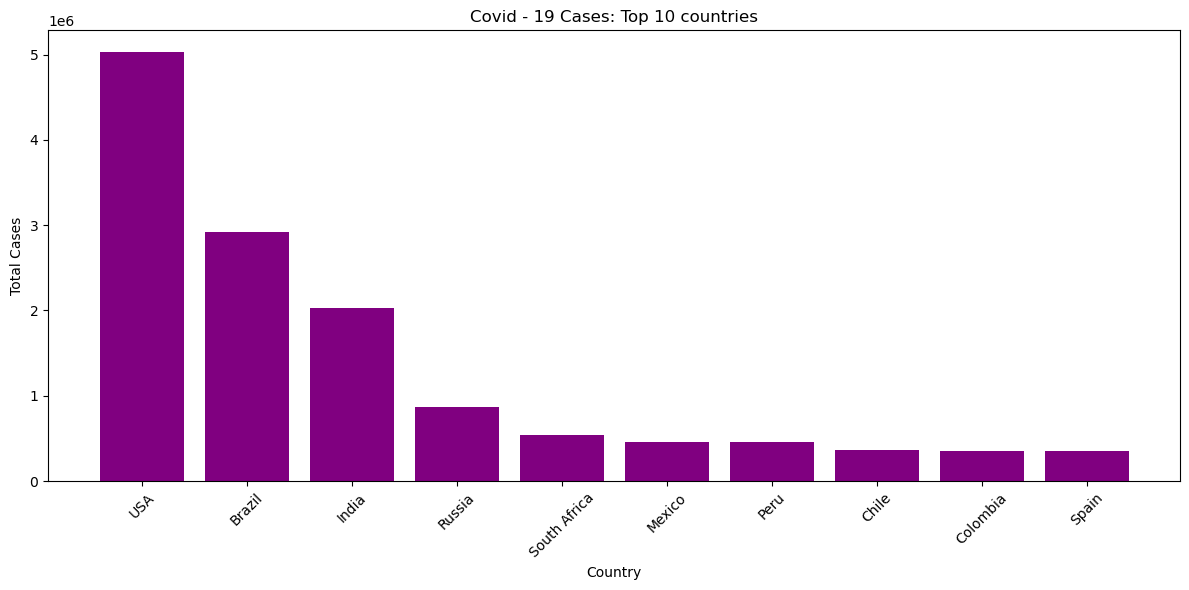

In [11]:
top_cases = df.nlargest(10, 'TotalCases')

plt.figure(figsize=(12,6))
plt.bar(top_cases['Country_Region'], top_cases['TotalCases'],color='purple')
plt.xticks(rotation=45)
plt.title('Covid - 19 Cases: Top 10 countries')
plt.xlabel('Country')
plt.ylabel('Total Cases')
plt.tight_layout()
plt.show()
        

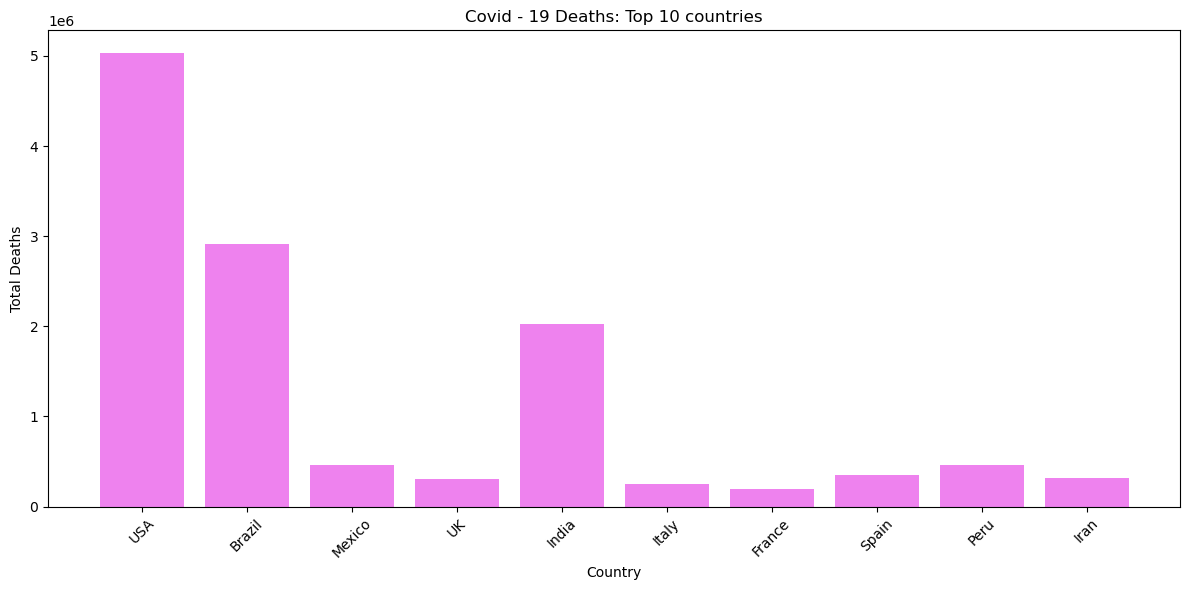

In [13]:
top_death = df.nlargest(10, 'TotalDeaths')

plt.figure(figsize=(12,6))
plt.bar(top_death['Country_Region'], top_death['TotalCases'],color='violet')
plt.xticks(rotation=45)
plt.title('Covid - 19 Deaths: Top 10 countries')
plt.xlabel('Country')
plt.ylabel('Total Deaths')
plt.tight_layout()
plt.show()

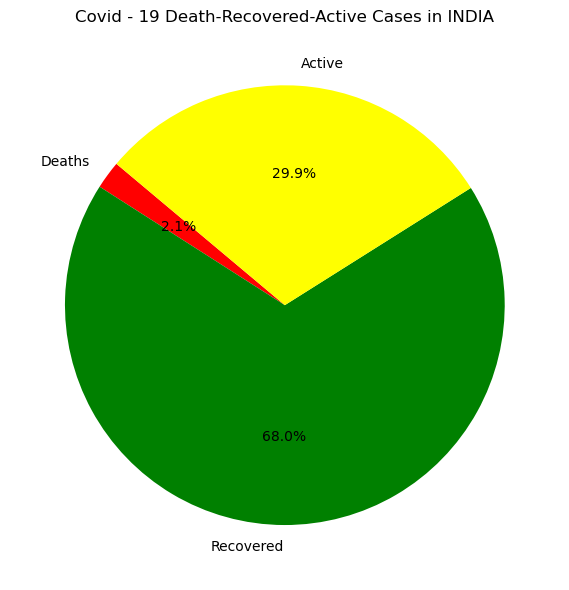

In [15]:
country = 'India'
row = df[df['Country_Region'] == country].iloc[0]

labels = ['Deaths', 'Recovered', 'Active']
sizes = [row['TotalDeaths'], row['TotalRecovered'], row['ActiveCases']]
colors = ['red', 'green', 'yellow']

plt.figure(figsize=(6, 6))
plt.pie(sizes, labels=labels, colors=colors, autopct='%1.1f%%', startangle=140)
plt.title('Covid - 19 Death-Recovered-Active Cases in INDIA')
plt.tight_layout()
plt.show()